In [1]:
Yofrom pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

In [2]:
random_state = 42
seed = 42

In [3]:
df = pd.read_csv("hotels.csv")

In [4]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

## Column Descriptions

Hotel booking data (City Hotel and Resort Hotel). Each row is one booking. The target is `is_canceled`.

| Column | Description |
|---|---|
| `hotel` | Which hotel: Resort Hotel or City Hotel |
| `is_canceled` | Target. 1 if the booking was canceled, 0 if not |
| `lead_time` | Days between the booking being entered and the arrival date |
| `arrival_date_year` | Year of arrival |
| `arrival_date_month` | Month of arrival (name) |
| `arrival_date_week_number` | Week number of the year of arrival |
| `arrival_date_day_of_month` | Day of the month of arrival |
| `stays_in_weekend_nights` | Number of weekend nights (Sat/Sun) booked |
| `stays_in_week_nights` | Number of week nights (Mon-Fri) booked |
| `adults` | Number of adults |
| `children` | Number of children (4 missing) |
| `babies` | Number of babies |
| `meal` | Meal plan booked: BB (bed & breakfast), HB (half board), FB (full board), SC / Undefined (no meal package) |
| `country` | Guest's country of origin, as an ISO country code (488 missing) |
| `market_segment` | Market segment the booking came from (e.g. Direct, Corporate, Groups, Online TA, Offline TA/TO, Complementary). TA = travel agent, TO = tour operator |
| `distribution_channel` | Channel used to make the booking (e.g. Direct, Corporate, TA/TO, GDS) |
| `is_repeated_guest` | 1 if the guest has stayed before, 0 if not |
| `previous_cancellations` | Number of earlier bookings this guest canceled |
| `previous_bookings_not_canceled` | Number of earlier bookings this guest did not cancel |
| `reserved_room_type` | Room type code reserved |
| `assigned_room_type` | Room type code actually assigned (can differ from reserved) |
| `booking_changes` | Number of changes made to the booking before check-in or cancellation |
| `deposit_type` | No Deposit, Non Refund, or Refundable |
| `agent` | ID of the travel agency that made the booking (16,340 missing, meaning no agent) |
| `company` | ID of the company responsible for paying (112,593 missing, meaning no company) |
| `days_in_waiting_list` | Days the booking was on the waiting list before being confirmed |
| `customer_type` | Contract, Group, Transient, or Transient-Party |
| `adr` | Average daily rate: total lodging revenue divided by number of nights |
| `required_car_parking_spaces` | Number of parking spaces requested |
| `total_of_special_requests` | Number of special requests (e.g. high floor, twin beds) |
| `reservation_status` | Leak. Final status: Canceled, Check-Out, or No-Show. Directly encodes `is_canceled` |
| `reservation_status_date` | Leak. Date the final status was set. Only known after the outcome |


## 1.1

- Working with a dataset that has 32 columns and 119,390 rows, so we seem to have the right data source.
### The Leak
- reservation_status and reservation_status_date are both the leaks. We are trying to model whether bookings will cancel, so our client knows wich one to overbook against. These two columns leak the outcome. "pd.crosstab(df["reservation_status"], df["is_canceled"])" confirms that, showing that a model fed this column would likely get a high accuracy, and not learning the underlying relationship between the data.
- 
#### Missing Values and what they mean
- country:  missing 488 rows, meaning that the hotel did not account or record the guests' country of origin. Useful data, likely has some signal, but miniscule compared to the entire database (119390/488). The best course if action is to replace NaN with "Unknown". Helps that "Unknown" is not a label currently held by "company".

- agent = 16340 missing. This means that no travel agent was involved. Best course of action would be to add a column "has_agent" and fill with a binary identifier (yes or no). The values held by "agent" may  not provide relevant signaling to the model, unless there are specific agents that have irregular cancellation rates, so it may be worth keeping the column and rendering the missing rows as "None".
  
- company = 112593 missing values. This means no company is paying for the stay. Best course of action would be to add a column "has_company" and fill with a binary identifier (yes or no) and drop the column, as it likely produces no valuable signal and is almost entirely pure (112593/119390 = 0.94). Would not be beneficial to keep the values held by this row, like I did with agent, as the specific companies with irregular cancel rates are likely too small to create a predictive relationship (and I don't want to do weighted random sampling for a rare case)

- children = 4 missing. We can assume this was a misinput or an oversight. Also, declared as a floating point number, but should be a regular integer, since the number of children are a discrete value. Means the # of children attending. Fill with zero, too few to matter.

- adr (average daily rate_ : Looking at the desription of adr, the maximum is 5400 and the minimum is -6.3. There are also 1959 rows with an adr of 0. A negative number should be impossible, and a maximum value is extremely high compared to the median price. My motion is to Drop the rows with the negative adr and extreme adr. For the 1959 rows, I will drop 794 rows out of the 1959. I came to this number by finding a way to determine if an actual stay happened. I did that by comparing the adr, total nights stayed (weekends + week days), number of adults, and number of children + babies. If a row has an adr of 0, no adults, and no children, I reason that these stays are non existent and neglile. For the rows that have an adr of 0, but record that there is 1 or more nights and adults recorded is possible that these rows could be complementary visits or zero cost visit (hotel points, coupons, etc.) so I did not remove these rows.

### Other Cleaning Stuff
- Duplicates: After doing the granular cleaning offered by the 1.1 prompt, a basic step is to track the duplicates across the dataset. No booking ID exists, so I can't tell repeated records from coincidentally identical bookings. Dropped them so the same row can't end up in both train and test, which would inflate accuracy. After cleaning the duplicates, the cancel rate dropped from 37% to 27.5%. This i a big drop off and it is possible that some of the data tracked in this dataset was a logging of bookings made, and the dataset may be a result of customer bookings combined with admin room changes that tracks changes using the same database. I plan to compare a model trained with duplicates and without. I expect these two models will differ in their feature understanding.

### Obvious Leak 

In [5]:
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [6]:
df = df.drop(columns=["reservation_status", "reservation_status_date"])
df.shape

(119390, 30)

In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [8]:
df.shape

(119390, 30)

In [9]:
df.isna().sum()             # count of NaN values per column

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

## country

In [10]:
df["country"].unique()

<ArrowStringArray>
['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA',   nan, 'ROU', 'NOR', 'OMN',
 ...
 'ATA', 'GTM', 'ASM', 'MRT', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO']
Length: 178, dtype: str

In [11]:
print("Unknown" in df["country"].unique())

False


In [12]:
df["country"].isna().sum() #473 rows under "country" hold an NaN

np.int64(488)

In [13]:
df["country"] = df["country"].fillna("Unknown") #remove the values holding NaN in country
print(df["country"].isna().sum()) #488 rows under "country" now hold "Unknown", should return 0

0


### agent

In [14]:
df["agent"].unique()

array([ nan, 304., 240., 303.,  15., 241.,   8., 250., 115.,   5., 175.,
       134., 156., 243., 242.,   3., 105.,  40., 147., 306., 184.,  96.,
         2., 127.,  95., 146.,   9., 177.,   6., 143., 244., 149., 167.,
       300., 171., 305.,  67., 196., 152., 142., 261., 104.,  36.,  26.,
        29., 258., 110.,  71., 181.,  88., 251., 275.,  69., 248., 208.,
       256., 314., 126., 281., 273., 253., 185., 330., 334., 328., 326.,
       321., 324., 313.,  38., 155.,  68., 335., 308., 332.,  94., 348.,
       310., 339., 375.,  66., 327., 387., 298.,  91., 245., 385., 257.,
       393., 168., 405., 249., 315.,  75., 128., 307.,  11., 436.,   1.,
       201., 183., 223., 368., 336., 291., 464., 411., 481.,  10., 154.,
       468., 410., 390., 440., 495., 492., 493., 434.,  57., 531., 420.,
       483., 526., 472., 429.,  16., 446.,  34.,  78., 139., 252., 270.,
        47., 114., 301., 193., 182., 135., 350., 195., 352., 355., 159.,
       363., 384., 360., 331., 367.,  64., 406., 16

In [15]:
df["has_agent"] = df["agent"].notna().astype(int)     # flag FIRST, while the blanks still exist

In [16]:
df["agent"] = df["agent"].fillna(0).astype(int).astype(str)   # IDs as text labels

In [17]:
df.loc[df["has_agent"] == 0, "agent"] = "None"

In [18]:
print(df["has_agent"].value_counts())   # about 16,000 zeros
print(df["agent"].nunique())            # number of distinct agents

has_agent
1    103050
0     16340
Name: count, dtype: int64
334


### company

In [19]:
print(df["company"].isna().sum())

112593


In [20]:
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns=["company"])

In [21]:
print(df["has_company"].sum())

6797


In [22]:
print(df["has_company"].value_counts())   # about 94% zeros
print("company" in df.columns)            # False

has_company
0    112593
1      6797
Name: count, dtype: int64
False


### children

In [23]:
print(df["children"].isna().sum())   # 4

4


In [24]:
df["children"] = df["children"].fillna(0).astype(int)
print(df["children"])

0         0
1         0
2         0
3         0
4         0
         ..
119385    0
119386    0
119387    0
119388    0
119389    0
Name: children, Length: 119390, dtype: int64


In [25]:
print(df["children"].isna().sum())   # should be 0
print(df["children"].dtype)          # int64

0
int64


In [26]:
print(df.isna().sum().sum())   # No NaN values
df.shape

0


(119390, 31)

### adr (Average Daily Rate)

In [27]:
#Tackling strange values in adr
df["adr"].describe()


count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

In [28]:
# check how many rows hold a negative adr
print("negative:", (df["adr"] < 0).sum())

negative: 1


In [29]:
# check how many rows hold an xtreme value
print("rows over 500:", (df["adr"] > 500).sum())

print("rows over 1000:", (df["adr"] > 1000).sum())

print("rows zero:", (df["adr"] == 0).sum())

print("rows less than or equal to zero:", (df["adr"] <= 0).sum())

print("rows equal to zero:", (df["adr"] == 0).sum())


rows over 500: 3
rows over 1000: 1
rows zero: 1959
rows less than or equal to zero: 1960
rows equal to zero: 1959


In [30]:
# all negative rows less than or equal to 0 adr
df[df["adr"] <= 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,None,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,4,No Deposit,None,0,Transient,0.0,0,0,0,0
125,Resort Hotel,0,32,2015,July,27,4,0,1,4,...,2,No Deposit,None,0,Transient,0.0,0,1,0,0
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,0,No Deposit,240,0,Transient,0.0,0,2,1,0
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,0,No Deposit,250,0,Transient,0.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,7,No Deposit,98,0,Transient-Party,0.0,0,0,1,0
118762,City Hotel,0,1,2017,August,34,24,0,1,2,...,1,No Deposit,None,0,Transient,0.0,0,3,0,0
118963,City Hotel,0,1,2017,August,35,27,0,0,2,...,0,No Deposit,None,0,Transient,0.0,0,0,0,0
119102,City Hotel,0,518,2017,August,34,26,2,1,1,...,1,No Deposit,229,0,Transient-Party,0.0,0,0,1,0


In [31]:
#all rows over 1000 adr
df[df["adr"] > 1000]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,1,Non Refund,12,0,Transient,5400.0,0,0,1,0


In [32]:
# all rows between 500 and 100
df[(df["adr"] > 500) & (df["adr"] <= 1000)][["hotel", "adr", "market_segment", "arrival_date_month"]]

,hotel,adr,market_segment,arrival_date_month
15083,Resort Hotel,508.0,Corporate,July
111403,City Hotel,510.0,Offline TA/TO,May


In [33]:
df.loc[11494]

hotel                             Resort Hotel
is_canceled                                  1
lead_time                                  150
arrival_date_year                         2017
arrival_date_month                         May
arrival_date_week_number                    19
arrival_date_day_of_month                   11
stays_in_weekend_nights                      2
stays_in_week_nights                         3
adults                                       2
children                                     0
babies                                       0
meal                                        BB
country                                    BEL
market_segment                       Online TA
distribution_channel                     TA/TO
is_repeated_guest                            0
previous_cancellations                       0
previous_bookings_not_canceled               0
reserved_room_type                           A
assigned_room_type                           A
booking_chang

In [34]:
df.loc[79731]

hotel                                City Hotel
is_canceled                                   1
lead_time                                   350
arrival_date_year                          2016
arrival_date_month                    September
arrival_date_week_number                     40
arrival_date_day_of_month                    30
stays_in_weekend_nights                       1
stays_in_week_nights                          2
adults                                        2
children                                      0
babies                                        0
meal                                         BB
country                                     PRT
market_segment                    Offline TA/TO
distribution_channel                      TA/TO
is_repeated_guest                             0
previous_cancellations                        1
previous_bookings_not_canceled                0
reserved_room_type                            A
assigned_room_type                      

In [35]:
df[df["adr"] == 0]["market_segment"].value_counts()

market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Corporate         82
Aviation           6
Name: count, dtype: int64

In [36]:
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
guests = df["adults"] + df["children"].fillna(0) + df["babies"]

In [37]:
nights.info()

<class 'pandas.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: None
Non-Null Count   Dtype
--------------   -----
119390 non-null  int64
dtypes: int64(1)
memory usage: 932.9 KB


In [38]:
guests.info()

<class 'pandas.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: None
Non-Null Count   Dtype
--------------   -----
119390 non-null  int64
dtypes: int64(1)
memory usage: 932.9 KB


In [39]:
bad = (df["adr"] < 0) | (df["adr"] > 1000) | (nights == 0) | (guests == 0)
print("rows to drop:", bad.sum())

rows to drop: 827


In [40]:
zero = df[df["adr"] == 0]
print("zero adr rows:", len(zero))

zero adr rows: 1959


In [41]:
zero_nights = zero[(zero["stays_in_weekend_nights"] + zero["stays_in_week_nights"]) == 0]
print("zero adr AND zero nights:", len(zero_nights))

zero adr AND zero nights: 715


In [42]:
no_guests = zero[(zero["adults"] + zero["children"].fillna(0) + zero["babies"]) == 0]
print("zero adr AND no guests:", len(no_guests))

zero adr AND no guests: 149


In [43]:
has_no_nights = (zero["stays_in_weekend_nights"] + zero["stays_in_week_nights"]) == 0
has_no_guests = (zero["adults"] + zero["children"].fillna(0) + zero["babies"]) == 0

In [44]:
to_remove = zero[has_no_nights | has_no_guests]   # | "either one"
remaining = zero[~(has_no_nights | has_no_guests)]  # ~  "not"

In [45]:
print("removed:  ", len(to_remove))
print("remaining:", len(remaining))
print("check:    ", len(to_remove) + len(remaining))   # should be 1959

removed:   794
remaining: 1165
check:     1959


In [46]:
df.shape

(119390, 31)

In [47]:
#drop the useless rows.
df = df[~bad].copy()

In [48]:
#create a new column to track which stays have adr = 0
df["adr_zero"] = (df["adr"] == 0).astype(int)

In [49]:
print(df.shape)             
print(df["adr_zero"].sum()) 

(118563, 32)
1165


In [50]:
before = pd.read_csv("hotels.csv", low_memory=False)["is_canceled"].mean()
print("cancel rate before:", round(before, 4))
print("cancel rate after: ", round(df["is_canceled"].mean(), 4))


cancel rate before: 0.3704
cancel rate after:  0.3726


In [51]:
df["adr_zero"].value_counts()

adr_zero
0    117398
1      1165
Name: count, dtype: int64

In [52]:
df.shape

(118563, 32)

### Duplicates

In [53]:
df.duplicated().sum()

np.int64(32189)

In [54]:
print("extra copies (what .duplicated() counts):", df.duplicated().sum())
print("all rows involved, originals + copies:  ", df.duplicated(keep=False).sum())

extra copies (what .duplicated() counts): 32189
all rows involved, originals + copies:   40350


In [55]:

print("shape before:", df.shape)
print("exact duplicate rows:", df.duplicated().sum())


shape before: (118563, 32)
exact duplicate rows: 32189


In [56]:
df = df.drop_duplicates().reset_index(drop=True)

In [57]:
print("shape after: ", df.shape)
print("duplicates left:", df.duplicated().sum())   # should be 0

shape after:  (86374, 32)
duplicates left: 0


In [58]:
print(df.shape)
print("duplicates left:", df.duplicated().sum())   # should be 0
print("is_canceled rate:", round(df["is_canceled"].mean(), 4))

(86374, 32)
duplicates left: 0
is_canceled rate: 0.2747


In [59]:
# Cancel rates on the cleaned data (quoted in the 1.1 summary table)
print(df.groupby("adr_zero")["is_canceled"].mean().round(3))
print(df.groupby("has_agent")["is_canceled"].mean().round(3))

adr_zero
0    0.276
1    0.139
Name: is_canceled, dtype: float64
has_agent
0    0.126
1    0.298
Name: is_canceled, dtype: float64


### Unique value investigation, more leaks?

In [60]:
df["meal"].unique()

<ArrowStringArray>
['BB', 'FB', 'HB', 'SC', 'Undefined']
Length: 5, dtype: str

In [61]:
df[df["meal"] == "Undefined"]["is_canceled"].mean()

np.float64(0.15513626834381553)

In [62]:
undef = df[df["meal"] == "Undefined"]
print("rows:", len(undef))
print("cancel rate:", round(undef["is_canceled"].mean(), 4))

rows: 477
cancel rate: 0.1551


In [63]:
for m in ["Undefined", "SC"]:
    sub = df[df["meal"] == m]
    print(m, "| rows:", len(sub), "| cancel rate:", round(sub["is_canceled"].mean(), 4))

Undefined | rows: 477 | cancel rate: 0.1551
SC | rows: 9331 | cancel rate: 0.3556


In [64]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                            int64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [65]:
cat_cols = [c for c in df.columns if df[c].nunique() <= 20 and c != "is_canceled"]
for c in cat_cols:
    print(f"\n=== {c} ===")
    print(df.groupby(c)["is_canceled"].agg(["mean", "count"]).round(3).sort_values("mean"))


=== hotel ===
               mean  count
hotel                     
Resort Hotel  0.235  33507
City Hotel    0.300  52867

=== arrival_date_year ===
                    mean  count
arrival_date_year              
2015               0.203  13089
2016               0.264  41843
2017               0.319  31442

=== arrival_date_month ===
                     mean  count
arrival_date_month              
November            0.212   4898
January             0.221   4625
February            0.231   6015
October             0.237   6819
September           0.243   6626
March               0.244   7422
December            0.270   5028
May                 0.291   8258
April               0.303   7841
June                0.303   7700
July                0.319   9968
August              0.322  11174

=== stays_in_weekend_nights ===
                          mean  count
stays_in_weekend_nights              
19                       0.000      1
14                       0.000      1
13             

In [66]:
# parking: do canceled bookings ever have parking > 0?
pd.crosstab(df["required_car_parking_spaces"] > 0, df["is_canceled"])


is_canceled,0,1
required_car_parking_spaces,,
False,55358,23726
True,7290,0


In [67]:
# room: how often does assigned differ from reserved, split by outcome?
df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"])
print(df.groupby("room_changed")["is_canceled"].agg(["mean", "count"]))

                  mean  count
room_changed                 
False         0.313656  73721
True          0.047657  12653


In [68]:
df = df.drop(columns=["required_car_parking_spaces", "assigned_room_type", "room_changed"])
print(df.shape)
print([c for c in ["required_car_parking_spaces", "assigned_room_type", "room_changed"] if c in df.columns])   # should bef []

(86374, 30)
[]


In [69]:
print(df.groupby("booking_changes")["is_canceled"].agg(["mean", "count"]).head(6))
print(df.groupby(df["days_in_waiting_list"] > 0)["is_canceled"].agg(["mean", "count"]))


                     mean  count
booking_changes                 
0                0.301115  70704
1                0.138706  10771
2                0.202660   3459
3                0.152681    858
4                0.183140    344
5                0.175926    108
                          mean  count
days_in_waiting_list                 
False                 0.274105  85533
True                  0.334126    841


### 1.1 Summary of problems found

| # | Problem | Evidence | What I did | Why |
|---|---|---|---|---|
| 1 | Leak: `reservation_status`, `reservation_status_date` | Crosstab: Canceled/No-Show always `is_canceled=1`, Check-Out always 0 | Dropped both columns | They record the outcome, which isn't known at booking time. A model using them would look perfect but be useless. |
| 2 | `agent` missing (16,340) | Mostly Direct, Corporate and Groups market segments | Added `has_agent` (0/1); kept the ID as text, with `"None"` for missing | Blank means no agent was involved, not unknown. Cancel rate differs (13% without an agent vs 30% with one). |
| 3 | `company` missing (112,593, 94%) | Only 6,797 rows have a company | Added `has_company` (0/1); dropped the raw ID | Blank means no company is paying. Individual company IDs are too rare to learn from. |
| 4 | `country` missing (488) | 0.4% of rows | Filled with `"Unknown"` | Likely a data-entry gap. Keeps the rows, and the model can use the missingness. |
| 5 | `children` missing (4) | 4 of 119,390 rows | Filled with 0 | Too few to matter; 0 is the most common value. |
| 6 | `adr` negative / extreme | 1 row at -6.38, 1 row at 5,400 (median ~95) | Dropped both | A negative price is impossible; 5,400 is abt 50x typical and almost certainly an error. |
| 7 | `adr` = 0 | 1,959 rows; 680 are Complementary. After removing rows with no stay (see 8), 1,165 remain | Kept them and added `adr_zero` flag | Some are real complimentary stays. These rows cancel far less often (13.9% vs 27.6% for the rest), so the flag lets the model use that. |
| 8 | Bookings with no guests / no nights | Among the 1,959 zero-`adr` rows: 715 have zero nights and 149 have no guests (794 rows together) | Dropped 827 rows in total: those 794, the 2 `adr` outliers (row 6), and 31 other no-guest rows with a non-zero `adr` | No actual stay took place, so there is nothing to learn from. |
| 9 | Exact duplicate rows | 32,189 extra copies (27% of the data) | Dropped them (119,390 → 86,374 rows after all drops) | No booking ID, so I can't separate repeated records from coincidental matches. Dropping avoids the same row appearing in both train and test. The cancel rate fell from 37.0% to 27.5%, so the copies were mostly cancellations. |
| 10 | `meal` has `Undefined` (1,169) | Same meaning as `SC` (no package) but a wildly different cancel rate | Keep the two values separate |  Undefined bookings cancel less than half as often. With 477 rows, that gap is too large to be chance. If you merge them, I'd average 477 low-cancel rows into 9,331 higher-cancel rows and lose a real difference. |
| 13 | Leak: `required_car_parking_spaces` | Of 7,290 bookings with parking > 0, none were canceled (crosstab) | Dropped | Recorded at check-in, so it reveals the outcome. Not known at booking time. |
| 14 | Leak: `assigned_room_type` | Bookings where assigned room differs from reserved cancel 4.8% of the time vs 31.4% when unchanged | Dropped (kept `reserved_room_type`) | Room is assigned at check-in; canceled bookings never reach it. |
| 15 | `booking_changes` (borderline) | 0 changes: 30.1% cancel; 1+ changes: 14-20% | Kept, with a caveat | Counts changes up to check-in or cancellation, so it's partly measured at the outcome. The gap is moderate and doesn't look like a copy of the target, so I kept it. |

### 1.2 Cost matrix and the two trivial policies

I split the data first, because the trivial policies are priced on the training set and Part 1.3 says the test set must not be touched until Part 4. The split is stratified so train and test keep the same cancel rate.

In [70]:
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state)

print(len(X_train), len(X_test))
print(y_train.mean(), y_test.mean())   # should be nearly identical

69099 17275
0.27469283202361827 0.27467438494934876



(rows = what really happens, columns = what we predicted; positive class = "will cancel", which means we overbook):
The two mistakes are not equally expensive. A wrong overbook costs €150 and a missed cancellation costs €120.

In [71]:
cost_matrix = pd.DataFrame(
    [[0, 120], [150, 0]],
    index=["actually cancels", "actually shows up"],
    columns=["predict cancel (overbook)", "predict stays"])
cost_matrix

,predict cancel (overbook),predict stays
actually cancels,0,120
actually shows up,150,0


In [72]:
def total_cost(y_true, y_pred):
    fp = ((y_pred == 1) & (y_true == 0)).sum()   # overbooked, but the guest showed up -> 150 each
    fn = ((y_pred == 0) & (y_true == 1)).sum()   # did not overbook, room stayed empty -> 120 each
    return 150 * fp + 120 * fn

In [73]:
n_cancel = (y_train == 1).sum()
n_show   = (y_train == 0).sum()

cost_nobody    = 120 * n_cancel   # overbook nobody: pay 120 for every cancellation
cost_everybody = 150 * n_show     # overbook everybody: pay 150 for every guest who shows up

print("training bookings:", len(y_train), "| cancel:", n_cancel, "| show up:", n_show)
print("overbook nobody:    €", cost_nobody,    "| per booking: €", round(cost_nobody / len(y_train), 2))
print("overbook everybody: €", cost_everybody, "| per booking: €", round(cost_everybody / len(y_train), 2))

# check the helper function gives the same numbers
print(total_cost(y_train, np.zeros(len(y_train), dtype=int)) == cost_nobody)
print(total_cost(y_train, np.ones(len(y_train), dtype=int)) == cost_everybody)

training bookings: 69099 | cancel: 18981 | show up: 50118
overbook nobody:    € 2277720 | per booking: € 32.96
overbook everybody: € 7517700 | per booking: € 108.8
True
True


### Results on the training set (69,099 bookings: 18,981 cancel, 50,118 show up)


- Overbook nobody is the cheaper policy, by about 3.3x. Most bookings (about 73%) do show up, so overbooking everyone means paying €150 to walk guests away far more often than we ever save by filling a cancelled room.
- This is the number to beat Any model we build only has value if its total cost on the training data is below €2,277,720 (€32.96 per booking). A model that cannot beat "do nothing" is not worth deploying.
- What could go wrong: the brief says about 37% of bookings cancel, but after removing duplicates my data has a cancel rate of 27.5%. The duplicates were mostly cancellations, so the cost of overbooking nobody here is probably lower than what the hotel actually experiences. The real baseline is likely higher, which makes a model look more valuable in practice than in these numbers.
- Break-even preview: overbooking only pays when the chance of cancelling p satisfies p x 120 > (1 - p) x 150, which is p > 150 / 270, about 0.556. That is why the best threshold in 1.3 will not be 0.5.

## 1.3 Logistic regression and SVM

**Setup decisions.**
- The 20% holdout was already split off in 1.2. It is not used again until Part 4.
- `arrival_date_year` is **not** a feature. The hotel will score future years, and a model that learned "2016 means X" has nothing to say about 2018. I use it only to build the time split in 4.1.
- Numeric columns are standardised, which logistic regression and the SVM need. Categoricals are one-hot encoded.
- `country` (172 values) and `agent` (318 values) would blow up the width. Values seen fewer than 100 times are pooled into one "rare" bucket, and values never seen in training fall into it at prediction time.
- All encoders and scalers sit inside the pipeline, so each CV fold fits them on its own training part only.
- Every model is scored by out-of-fold predictions from the same stratified 5 folds.

**Why the best threshold is not 0.5.** The two mistakes cost different amounts. Flag a booking when `P(cancel) x 120 > (1 - P(cancel)) x 150`, i.e. when `P(cancel) > 150 / 270 = 0.556`. A wrong overbook (150) hurts more than a missed cancellation (120), so the model should be a little more certain than a coin flip before it acts. The scan found 0.545, close to that theoretical value. The gain over 0.5 is small for logistic regression (about €13k of €1.88M), but the principle matters more for models whose probabilities are less well calibrated. Note that AUC does not depend on the threshold at all, so it cannot tell us where to cut.

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import time, json

# arrival_date_year is kept aside (for the time split in 4.1) but is NOT a model feature
year_all = df["arrival_date_year"]
feat_cols = [c for c in X.columns if c != "arrival_date_year"]
num_feats = X[feat_cols].select_dtypes("number").columns.tolist()
cat_feats = X[feat_cols].select_dtypes(exclude="number").columns.tolist()

def make_prep(scale):
    # country (172 values) and agent (318 values) are high cardinality: values seen < 100 times
    # are pooled into one "rare" bucket, and unseen values at predict time go there too
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_feats),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100,
                              sparse_output=False), cat_feats)])

cv5 = StratifiedKFold(5, shuffle=True, random_state=random_state)
Xtr = X_train[feat_cols]; ytr = y_train
oof = {}        # out-of-fold scores of every model, kept for the threshold choice in Part 4
results = []    # one row per model

def best_threshold(y_true, score):
    """Scan thresholds, return (threshold, cost) with the lowest total euro cost."""
    y = np.asarray(y_true)
    grid = np.unique(np.quantile(score, np.linspace(0.01, 0.99, 197)))
    costs = [total_cost(y, (score >= t).astype(int)) for t in grid]
    i = int(np.argmin(costs))
    return grid[i], costs[i]

def summarize(name, y_true, score, prob=True):
    y = np.asarray(y_true)
    t, c = best_threshold(y, score)
    pred = (score >= t).astype(int)
    row = dict(model=name, AUC=roc_auc_score(y, score), threshold=t, share_flagged=pred.mean(),
               recall=recall_score(y, pred), precision=precision_score(y, pred),
               cost=c, cost_per_booking=c / len(y))
    row["cost_at_0.5"] = total_cost(y, (score >= 0.5).astype(int)) if prob else np.nan
    return row

def cv_scores(name, pipe, method="predict_proba", n_jobs=5):
    t0 = time.time()
    s = cross_val_predict(pipe, Xtr, ytr, cv=cv5, method=method, n_jobs=n_jobs)
    s = s[:, 1] if s.ndim == 2 else s
    oof[name] = s
    results.append(summarize(name, ytr, s, prob=(method == "predict_proba")))
    print(f"{name}: {time.time()-t0:.0f}s")
    return s

print(len(feat_cols), "features:", len(num_feats), "numeric,", len(cat_feats), "categorical")

28 features: 18 numeric, 10 categorical


In [75]:
lr_pipe = make_pipeline(make_prep(scale=True), LogisticRegression(max_iter=1000, random_state=random_state))
_ = cv_scores("Logistic regression", lr_pipe)
pd.DataFrame(results).round(3)

Logistic regression: 4s


,model,AUC,threshold,share_flagged,recall,precision,cost,cost_per_booking,cost_at_0.5
0,Logistic regression,0.831,0.545,0.16,0.404,0.694,1864950,26.99,1878360


### The SVM at scale

Cells below answer "how much AUC do we give up by subsampling?". An RBF SVM costs somewhere between O(n^2) and O(n^3) in the training rows. The fit time grows about 6x going from 20k to 40k rows (11s to 64s), so the full 59k rows would take several minutes **per fold**.

Result on a fixed 10,000-row validation set: AUC rises from 0.809 (2.5k rows) to 0.844 (20k) and 0.854 (40k). Each doubling buys less, and 20k gives up only about 0.01 AUC against 40k at 1/6 of the time. I use **20,000 rows per fold** and score the full held-out fold, so the number is comparable with logistic regression's. A fair caveat: the SVM is still slightly under-trained, so its true full-data AUC is probably a little above what I report.

**CV results (training set, cost at the cost-minimising threshold):**

| model | AUC | recall | precision | total cost | per booking |
|---|---|---|---|---|---|
| Overbook nobody | - | 0 | - | €2,277,720 | €32.96 |
| Logistic regression | 0.831 | 0.40 | 0.69 | €1,864,950 | €26.99 |
| SVM (RBF, 20k subsample) | 0.852 | 0.51 | 0.74 | €1,636,170 | €23.68 |

Both beat the trivial policies. The SVM is clearly better (about €3.3 per booking), which tells us the signal is nonlinear (interactions such as agent x country x lead time) and that a straight line leaves money on the table. The SVM's threshold (-0.037) is on its decision-function score, not a probability, because I did not calibrate it.

In [76]:
# How much AUC do we give up by training the SVM on a subsample?
# Fixed validation set of 10,000 rows from the training data; SVM trained on growing stratified subsamples.
rest_idx, val_idx = train_test_split(Xtr.index, test_size=10000, stratify=ytr, random_state=random_state)
rows = []
for n in [2500, 5000, 10000, 20000, 40000]:
    sub_idx, _ = train_test_split(rest_idx, train_size=n, stratify=ytr.loc[rest_idx], random_state=random_state)
    t0 = time.time()
    svm = make_pipeline(make_prep(scale=True), SVC(kernel="rbf", random_state=random_state))
    svm.fit(Xtr.loc[sub_idx], ytr.loc[sub_idx])
    auc = roc_auc_score(ytr.loc[val_idx], svm.decision_function(Xtr.loc[val_idx]))
    rows.append(dict(train_rows=n, val_AUC=auc, fit_plus_predict_seconds=time.time() - t0))
lr_full = lr_pipe.fit(Xtr.loc[rest_idx], ytr.loc[rest_idx])
print("Logistic regression on all", len(rest_idx), "rows, same validation set: AUC =",
      round(roc_auc_score(ytr.loc[val_idx], lr_full.predict_proba(Xtr.loc[val_idx])[:, 1]), 4))
svm_exp = pd.DataFrame(rows); svm_exp.round(4)

Logistic regression on all 59099 rows, same validation set: AUC = 0.8209


,train_rows,val_AUC,fit_plus_predict_seconds
0,2500,0.8092,0.6977
1,5000,0.8195,1.5058
2,10000,0.8338,3.9803
3,20000,0.8443,14.2956
4,40000,0.8544,79.8577


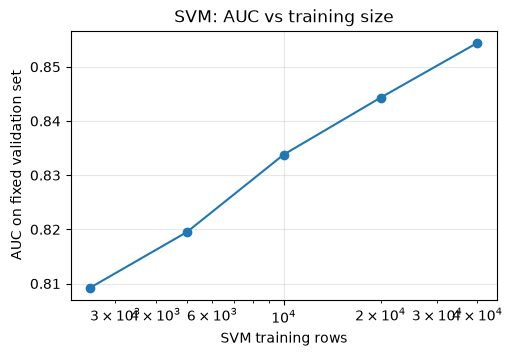

In [77]:
plt.figure(figsize=(5.5, 3.5))
plt.plot(svm_exp.train_rows, svm_exp.val_AUC, "o-")
plt.xscale("log"); plt.xlabel("SVM training rows"); plt.ylabel("AUC on fixed validation set")
plt.title("SVM: AUC vs training size"); plt.grid(alpha=.3); plt.show()

In [78]:
# Stratified 5-fold CV for the SVM: inside each fold, train on a 20,000-row stratified subsample of the
# training folds, but score the whole held-out fold (so the AUC is comparable with the logistic regression's).
SVM_N = 20000
def svm_fold(tr, va):
    sub, _ = train_test_split(tr, train_size=SVM_N, stratify=ytr.iloc[tr], random_state=random_state)
    m = make_pipeline(make_prep(scale=True), SVC(kernel="rbf", random_state=random_state))
    m.fit(Xtr.iloc[sub], ytr.iloc[sub])
    return va, m.decision_function(Xtr.iloc[va])

t0 = time.time()
parts = Parallel(n_jobs=5)(delayed(svm_fold)(tr, va) for tr, va in cv5.split(Xtr, ytr))
s = np.zeros(len(Xtr))
for va, d in parts: s[va] = d
oof["SVM (RBF, 20k subsample)"] = s
results.append(summarize("SVM (RBF, 20k subsample)", ytr, s, prob=False))
print(f"{time.time()-t0:.0f}s")
res13 = pd.DataFrame(results); res13.round(3)

41s


,model,AUC,threshold,share_flagged,recall,precision,cost,cost_per_booking,cost_at_0.5
0,Logistic regression,0.831,0.545,0.16,0.404,0.694,1864950,26.990,1878360.0
1,"SVM (RBF, 20k subsample)",0.852,-0.037,0.19,0.509,0.737,1636170,23.679,NaN


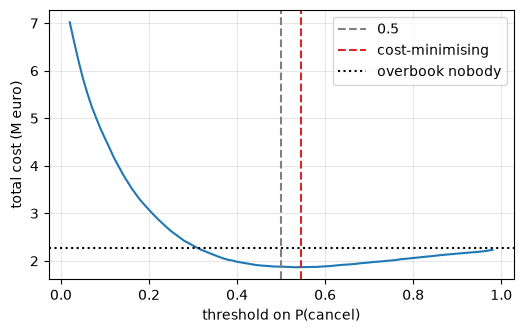

In [79]:
# Cost as a function of the threshold (logistic regression): the minimum is not at 0.5
ts = np.linspace(0.02, 0.98, 97)
c = [total_cost(ytr, (oof["Logistic regression"] >= t).astype(int)) for t in ts]
plt.figure(figsize=(6, 3.5)); plt.plot(ts, np.array(c) / 1e6)
plt.axvline(0.5, color="grey", ls="--", label="0.5")
plt.axvline(res13.loc[0, "threshold"], color="C3", ls="--", label="cost-minimising")
plt.axhline(cost_nobody / 1e6, color="k", ls=":", label="overbook nobody")
plt.xlabel("threshold on P(cancel)"); plt.ylabel("total cost (M euro)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## Part 2. Ensembles

### 2.1 Diagnose a single tree

Train vs 5-fold CV AUC, by depth:

| depth | train AUC | CV AUC |
|---|---|---|
| 2 | 0.679 | 0.677 |
| 4 | 0.818 | 0.818 |
| 8 | 0.874 | 0.862 |
| 16 | 0.950 | 0.817 |
| unlimited (grew to depth 46, 10,657 leaves) | 1.000 | 0.726 |

- **Depth 2: bias.** Training and CV AUC are both low (0.68) and almost equal. The tree is too simple to describe the data, and more data would not fix it.
- **Unlimited: variance.** Training AUC is 1.000 and CV AUC is 0.726. The tree memorised the training set, with roughly one leaf per five bookings, so its answers change with every sample.
- The CV optimum for a single tree is around depth 8, which is a bias-variance compromise.

In [80]:
depths = [2, 4, 8, 16, None]
tree_rows = []
for d in depths:
    pipe = make_pipeline(make_prep(scale=False), DecisionTreeClassifier(max_depth=d, random_state=random_state))
    r = cross_validate(pipe, Xtr, ytr, cv=cv5, scoring="roc_auc", return_train_score=True, n_jobs=5)
    tree_rows.append(dict(max_depth=str(d), train_AUC=r["train_score"].mean(), cv_AUC=r["test_score"].mean()))
full_tree = make_pipeline(make_prep(scale=False), DecisionTreeClassifier(random_state=random_state)).fit(Xtr, ytr)
print("unlimited tree actually grew to depth", full_tree[-1].get_depth(), "with", full_tree[-1].get_n_leaves(), "leaves")
tree_df = pd.DataFrame(tree_rows); tree_df.round(4)

unlimited tree actually grew to depth 46 with 10657 leaves


,max_depth,train_AUC,cv_AUC
0,2,0.6793,0.6769
1,4,0.8181,0.8177
2,8,0.8738,0.8619
3,16,0.9501,0.8166
4,None,1.0000,0.7258


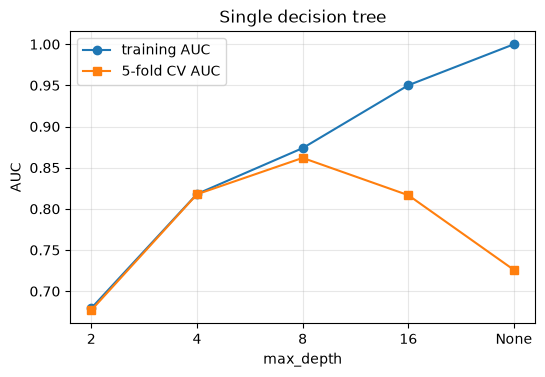

In [81]:
plt.figure(figsize=(6, 3.8))
plt.plot(tree_df.max_depth, tree_df.train_AUC, "o-", label="training AUC")
plt.plot(tree_df.max_depth, tree_df.cv_AUC, "s-", label="5-fold CV AUC")
plt.xlabel("max_depth"); plt.ylabel("AUC"); plt.legend(); plt.grid(alpha=.3); plt.title("Single decision tree"); plt.show()

**Prediction, written before running 2.2.**
- **Depth-2 tree: boosting will help more than bagging.** Boosting builds a sequence of trees, each correcting the last one's mistakes, so it adds capacity. Bagging averages bootstrap copies of the same weak tree. Averaging does not remove bias, and every copy makes the same systematic mistake.
- **Unlimited tree: bagging will help more than boosting.** Averaging many high-variance trees cancels their noise. Boosting already-overfit trees should add little, since there is no bias left to remove.

Implementation notes: bagging uses scikit-learn's `BaggingClassifier` (100 depth-2 trees, 50 unlimited ones, for run time). Boosting uses scikit-learn's `HistGradientBoostingClassifier` (300 rounds with at most 4 leaves for the "depth-2" model, 100 rounds with no depth or leaf cap and `min_samples_leaf=1` for the "unlimited" one), learning rate 0.1.

In [82]:
def tree(d): return DecisionTreeClassifier(max_depth=d, random_state=random_state)
prep_t = lambda: make_prep(scale=False)
ensembles = {
  "Bagging, depth-2 trees":    make_pipeline(prep_t(), BaggingClassifier(tree(2), n_estimators=100, random_state=random_state)),
  "Bagging, unlimited trees":  make_pipeline(prep_t(), BaggingClassifier(tree(None), n_estimators=50, random_state=random_state)),
  "Boosting, depth-2 trees":   make_pipeline(prep_t(), HistGradientBoostingClassifier(max_depth=2, max_leaf_nodes=4, max_iter=300, learning_rate=0.1, early_stopping=False, random_state=random_state)),
  "Boosting, unlimited trees": make_pipeline(prep_t(), HistGradientBoostingClassifier(max_depth=None, max_leaf_nodes=None, min_samples_leaf=1, l2_regularization=0.0, max_iter=100, learning_rate=0.1, early_stopping=False, random_state=random_state)),
  "Random forest (200 trees)": make_pipeline(prep_t(), RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=random_state)),
}
for name, pipe in ensembles.items():
    cv_scores(name, pipe)
res_all = pd.DataFrame(results)
res_all.round(3)

Bagging, depth-2 trees: 13s


Bagging, unlimited trees: 25s


Boosting, depth-2 trees: 20s


Boosting, unlimited trees: 261s


Random forest (200 trees): 15s


,model,AUC,threshold,share_flagged,recall,precision,cost,cost_per_booking,cost_at_0.5
0,Logistic regression,0.831,0.545,0.160,0.404,0.694,1864950,26.990,1878360.0
1,"SVM (RBF, 20k subsample)",0.852,-0.037,0.190,0.509,0.737,1636170,23.679,NaN
2,"Bagging, depth-2 trees",0.755,0.374,0.173,0.382,0.608,2107470,30.499,2277720.0
3,"Bagging, unlimited trees",0.885,0.580,0.205,0.565,0.758,1505340,21.785,1542900.0
4,"Boosting, depth-2 trees",0.872,0.512,0.195,0.523,0.737,1617330,23.406,1618860.0
5,"Boosting, unlimited trees",0.875,0.911,0.195,0.520,0.733,1631640,23.613,1675140.0
6,Random forest (200 trees),0.892,0.515,0.215,0.593,0.756,1471410,21.294,1473390.0


In [83]:
# the single trees from 2.1, scored the same way, for comparison
for d in [2, None]:
    nm = f"Single tree, depth {d}"
    cv_scores(nm, make_pipeline(prep_t(), tree(d)))
res_all = pd.DataFrame(results)
res_all[["model", "AUC", "threshold", "recall", "precision", "cost", "cost_per_booking"]].round(3)

Single tree, depth 2: 1s


Single tree, depth None: 2s


,model,AUC,threshold,recall,precision,cost,cost_per_booking
0,Logistic regression,0.831,0.545,0.404,0.694,1864950,26.990
1,"SVM (RBF, 20k subsample)",0.852,-0.037,0.509,0.737,1636170,23.679
2,"Bagging, depth-2 trees",0.755,0.374,0.382,0.608,2107470,30.499
3,"Bagging, unlimited trees",0.885,0.580,0.565,0.758,1505340,21.785
4,"Boosting, depth-2 trees",0.872,0.512,0.523,0.737,1617330,23.406
5,"Boosting, unlimited trees",0.875,0.911,0.520,0.733,1631640,23.613
6,Random forest (200 trees),0.892,0.515,0.593,0.756,1471410,21.294
7,"Single tree, depth 2",0.688,0.523,0.067,0.514,2305410,33.364
8,"Single tree, depth None",0.726,1.000,0.604,0.598,2059290,29.802


### 2.2 Did the prediction hold?

| model | CV AUC | cost per booking |
|---|---|---|
| Single tree, depth 2 | 0.688 | €33.36 |
| Bagging, depth-2 trees | 0.755 | €30.50 |
| Boosting, depth-2 trees | 0.872 | €23.41 |
| Single tree, unlimited | 0.726 | €29.80 |
| Bagging, unlimited trees | 0.885 | €21.79 |
| Boosting, unlimited trees | 0.875 | €23.61 |
| Random forest (200 trees) | **0.892** | **€21.29** |

**Prediction check.**
- **Depth-2: confirmed.** Boosting lifted AUC by +0.18 while bagging gave only +0.07. Bagging a weak tree barely moves it, because the averaged trees are almost identical.
- **Unlimited: confirmed, but with a surprise.** Bagging did win (0.885 vs 0.875), but boosting also helped a lot (+0.15). I expected it to do little.

**What surprised me.**
1. Boosting deep trees helped far more than "boosting only fixes bias" predicts. With learning rate 0.1 and 100 rounds, each deep tree contributes only a tenth of its vote, so the sum behaves like an average and also damps variance. The lectures' claim is a useful rule of thumb, not a law.
2. The deep boosted model's best threshold was 0.91, which is odd. Its probabilities are overconfident (it nearly memorises the training data), so the cost-optimal cut sits very high. The depth-2 boosted model sits at 0.51, which is well calibrated.
3. Depth-2 boosting (300 trees with 4 leaves each) is almost as good as the deep ensembles. That means most of the gain was in fixing bias, as the diagnosis said.
4. The random forest has the lowest cost, even though a plain bagged deep tree has almost the same AUC. Its extra trick, trying only a random subset of features at each split, de-correlates the trees, so averaging helps more.

**Caveats.** Thresholds are chosen on the same out-of-fold scores used to report cost, so costs are slightly optimistic. Differences of around €0.5 per booking between the top models are within the noise I would expect, and I don't read much into the ranking of the random forest versus bagging.

In [84]:
boosted = [m for m in res_all.model if m.startswith("Boosting")]
best_boost = res_all[res_all.model.isin(boosted)].sort_values("cost").model.iloc[0]
print("best boosted model by CV cost:", best_boost)

# Permutation importance on the raw columns: shuffle one column at a time on a held-out slice of the
# training data and see how much AUC drops. (sklearn's boosting has no built-in importances, and
# permuting the raw column keeps all the one-hot pieces of a column together.)
def perm_imp(model_name):
    pipe = clone(ensembles[model_name]).fit(Xtr.loc[rest_idx], ytr.loc[rest_idx])
    r = permutation_importance(pipe, Xtr.loc[val_idx], ytr.loc[val_idx], scoring="roc_auc", n_repeats=3,
                               random_state=random_state, n_jobs=5)
    return pd.Series(r.importances_mean, index=feat_cols).sort_values(ascending=False), pipe
imp_boost, pipe_boost = perm_imp(best_boost)
imp_rf, pipe_rf = perm_imp("Random forest (200 trees)")
# the random forest's built-in (impurity) importance, rolled up to the original column
rf_names = pipe_rf[0].get_feature_names_out()
def orig(n):
    if n.startswith("num__"): return n[5:]
    return next(c for c in sorted(cat_feats, key=len, reverse=True) if n[5:].startswith(c + "_"))
imp_rf_gini = pd.Series(pipe_rf[-1].feature_importances_, index=[orig(n) for n in rf_names]).groupby(level=0).sum().sort_values(ascending=False)
top = pd.DataFrame({"rank": range(1, 11), "boosted (AUC drop)": imp_boost.index[:10], "drop": imp_boost.values[:10].round(4),
                    "forest (AUC drop)": imp_rf.index[:10], "drop ": imp_rf.values[:10].round(4),
                    "forest (built-in impurity)": imp_rf_gini.index[:10], "share": (imp_rf_gini.values[:10]).round(3)})
top

best boosted model by CV cost: Boosting, depth-2 trees


,rank,boosted (AUC drop),drop,forest (AUC drop),drop,forest (built-in impurity),share
0,1,lead_time,0.0882,country,0.1079,lead_time,0.137
1,2,country,0.0852,agent,0.0876,country,0.128
2,3,agent,0.0655,lead_time,0.0611,adr,0.091
3,4,total_of_special_requests,0.0514,total_of_special_requests,0.0495,arrival_date_day_of_month,0.072
4,5,market_segment,0.0270,customer_type,0.0364,agent,0.070
5,6,customer_type,0.0184,market_segment,0.0272,arrival_date_month,0.066
6,7,previous_cancellations,0.0157,previous_cancellations,0.0093,arrival_date_week_number,0.064
7,8,previous_bookings_not_canceled,0.0079,booking_changes,0.0058,total_of_special_requests,0.061
8,9,deposit_type,0.0076,hotel,0.0053,stays_in_week_nights,0.049
9,10,booking_changes,0.0070,deposit_type,0.0051,market_segment,0.040


In [85]:
# direction of the top boosted features, in plain numbers
for c in imp_boost.index[:5]:
    if c in num_feats:
        q = pd.qcut(df[c], 4, duplicates="drop") if df[c].nunique() > 6 else df[c]
        print(f"\n{c}\n", df.groupby(q, observed=True)["is_canceled"].agg(["mean", "count"]).round(3))
    else:
        g_ = df.groupby(c)["is_canceled"].agg(["mean", "count"]).round(3)
        print(f"\n{c}\n", g_[g_["count"] >= 300].sort_values("mean").iloc[[0, 1, -2, -1]] if len(g_[g_["count"] >= 300]) > 4 else g_)


lead_time
                  mean  count
lead_time                   
(-0.001, 12.0]  0.109  22415
(12.0, 50.0]    0.288  21163
(50.0, 125.0]   0.335  21251
(125.0, 709.0]  0.374  21545

country
           mean  count
country              
Unknown  0.063    441
FIN      0.152    421
CHN      0.480    813
AGO      0.565    340

agent
         mean  count
agent              
243    0.057    475
28     0.059   1476
240    0.381  12878
9      0.400  28580

total_of_special_requests
                             mean  count
total_of_special_requests              
0                          0.332  43213
1                          0.225  28780
2                          0.213  11718
3                          0.172   2307
4                          0.106    320
5                          0.056     36

market_segment
                  mean  count
market_segment              
Corporate       0.120   4140
Complementary   0.122    682
Groups          0.260   4813
Online TA       0.354  51169


In [86]:
print(df.groupby("deposit_type")["is_canceled"].agg(["mean", "count"]).round(3))
nr = df[df.deposit_type == "Non Refund"]
print("\nNon Refund bookings by market segment (share of NR, cancel rate):")
print(pd.DataFrame({"share": nr.market_segment.value_counts(normalize=True), "cancel_rate": nr.groupby("market_segment").is_canceled.mean(), "n": nr.market_segment.value_counts()}).round(3))
print("\nTop agents among Non Refund bookings:")
ag = nr.groupby("agent").is_canceled.agg(["count", "mean"]).sort_values("count", ascending=False).head(6)
ag["share_of_NR"] = ag["count"] / len(nr); print(ag.round(3))
print("\nNon Refund by hotel:"); print(df.groupby("hotel").apply(lambda g: pd.Series({"NR_share": (g.deposit_type=="Non Refund").mean(), "NR_cancel_rate": g[g.deposit_type=="Non Refund"].is_canceled.mean()}), include_groups=False).round(3))
print("\nNon Refund by country (top 5):"); print(nr.groupby("country").is_canceled.agg(["count", "mean"]).sort_values("count", ascending=False).head(5).round(3))
print("\nNon Refund by lead time vs other:"); print(df.groupby("deposit_type").lead_time.median())
print("\nNon Refund by customer_type:"); print(nr.groupby("customer_type").is_canceled.agg(["count", "mean"]).round(3))

               mean  count
deposit_type              
No Deposit    0.267  85251
Non Refund    0.946   1016
Refundable    0.243    107

Non Refund bookings by market segment (share of NR, cancel rate):
                share  cancel_rate    n
market_segment                         
Corporate       0.063        0.703   64
Direct          0.009        0.667    9
Groups          0.633        0.958  643
Offline TA/TO   0.278        0.989  282
Online TA       0.018        0.833   18

Top agents among Non Refund bookings:
       count   mean  share_of_NR
agent                           
1        279  1.000        0.275
None     190  0.821        0.187
3         42  1.000        0.041
229       36  1.000        0.035
6         30  1.000        0.030
58        27  1.000        0.027

Non Refund by hotel:


              NR_share  NR_cancel_rate
hotel                                 
City Hotel       0.016           0.971
Resort Hotel     0.006           0.833

Non Refund by country (top 5):
         count   mean
country              
PRT        961  0.970
GBR         14  0.571
DEU         13  0.077
ESP          9  1.000
FRA          4  0.750

Non Refund by lead time vs other:
deposit_type
No Deposit     49.0
Non Refund    192.0
Refundable    169.0
Name: lead_time, dtype: float64

Non Refund by customer_type:
                 count   mean
customer_type                
Contract            28  1.000
Transient          841  1.000
Transient-Party    147  0.626


In [87]:
# Same comparison inside one market segment and one hotel, to see if the effect survives a like-for-like comparison
sub = df[(df.market_segment == "Groups")]
print("Groups only:"); print(sub.groupby("deposit_type").is_canceled.agg(["mean", "count"]).round(3))
sub = df[(df.market_segment == "Offline TA/TO")]
print("Offline TA/TO only:"); print(sub.groupby("deposit_type").is_canceled.agg(["mean", "count"]).round(3))
sub = df[(df.market_segment == "Online TA")]
print("Online TA only:"); print(sub.groupby("deposit_type").is_canceled.agg(["mean", "count"]).round(3))

Groups only:
               mean  count
deposit_type              
No Deposit    0.154   4090
Non Refund    0.958    643
Refundable    0.088     80
Offline TA/TO only:
               mean  count
deposit_type              
No Deposit    0.129  13417
Non Refund    0.989    282
Refundable    0.500      4
Online TA only:
               mean  count
deposit_type              
No Deposit    0.354  51137
Non Refund    0.833     18
Refundable    1.000     14


### 2.3 What drives cancellations

The best boosted model by CV cost is the depth-2 boosted model. scikit-learn's boosting has no built-in importances, so I use **permutation importance**: shuffle one raw column on a 10,000-row slice held out from the training data, and see how much AUC drops. Shuffling the raw column keeps all the one-hot pieces of `country` or `agent` together. The table above also shows the random forest's own impurity importance for comparison.

**Top ten (boosted):** lead_time, country, agent, total_of_special_requests, market_segment, customer_type, previous_cancellations, previous_bookings_not_canceled, deposit_type, booking_changes.

**Top five in plain English** (cancel rates from the cleaned data):
1. **Lead time.** Bookings made 12 days or less before arrival cancel 11% of the time; those made more than 125 days ahead cancel 37%. Flag far-ahead bookings.
2. **Guest country.** Some origins cancel at around half (China 48%, Angola 57%), others rarely (Finland 15%). Country partly stands in for which agent or channel sold the booking, so treat it as a pointer, not a cause.
3. **Agent.** The two biggest agents (9 and 240, about half of all bookings) cancel 40% and 38%. Agents 28 and 243 cancel under 6%. Review the contracts and cancellation terms with the first two.
4. **Special requests.** No request: 33% cancel. One request: 22%. Three or more: 17% or less. A guest who has told us what they want is invested, so a request is a good sign that they will turn up. Prompting guests for preferences at booking could help (it might only be a symptom, so test this).
5. **Market segment.** Online travel agencies cancel 35%, groups 26%, corporate 12%. Online agencies are by far the biggest segment (51k bookings), so they carry most of the problem.

**The odd one: non-refundable deposits.** Only 1,016 bookings (1.2% of the data) have one, and **94.6% of them cancel**, against 26.7% for no deposit.

What I found when I dug:
- **Where they come from:** 63% are Groups and 28% are Offline travel agents / tour operators. 97% are from Portugal (961 of 1,016). One agent (agent 1) accounts for 27.5% of them, and every one of its non-refundable bookings cancelled.
- **They look different in other ways too:** median lead time is 192 days against 49 for everyone else.
- **Like for like it does not go away:** inside Groups, no-deposit cancels 15% and non-refundable 96%. Inside Offline TA/TO, 13% against 99%.
- **My reading:** this is not guests ignoring a financial penalty. It looks like blocks of rooms booked early by a few agents and groups, who hold them as placeholders and release them. The rooms are paid for in a way the data does not show, or the "non-refundable" label is applied to bookings that are never meant to be used. The data cannot say which.
- **Would changing the deposit policy reduce cancellations?** I don't believe it would. Non-refundable is a marker of who the guest is, not a cause. Making ordinary online bookings non-refundable cannot be assumed to behave like a group-block booking, and there are only 18 non-refundable Online TA bookings, which is too few to learn from. If the hotel wants to know, run a controlled test on one segment. The model also leans on this pattern, so a policy change would break it (see risks in the memo).

**Comparing with the random forest.** Under permutation importance the lists share 9 of 10 features (the boosted model has `previous_bookings_not_canceled` where the forest has `hotel`), but the order differs. Country and agent top the forest, while lead time tops the boosted model. The forest's *built-in* impurity importance is quite different: it puts `adr`, `arrival_date_day_of_month`, `arrival_date_month` and `arrival_date_week_number` in its top ten, features which permutation shows barely matter (AUC drop around 0.005).

Why two good models rank features differently:
- **Correlated features share credit.** Country, agent, market segment and customer type describe the same underlying thing (who is booking and how). One model may lean on country and another on agent, with similar accuracy.
- **Impurity importance is biased toward features with many possible split points** (adr, day of month), because a deep tree can use them to carve up the training data, even when they do not generalise.
- **Boosting and forests use features differently.** Boosting with 4-leaf trees is forced to pick the few strongest features. A forest with deep trees spreads across many more.

A consequence for the hotel: treat the *group* of top features as the signal, not any single ranking.

## Part 3. Who are our guests

Segmentation uses a random sample of 10,000 non-cancelled bookings (`random_state=42`) and the nine starting features. I kept all nine. Features I considered adding (such as `hotel`, `market_segment`, or `meal`) are categorical and would need a different distance, so I use them only to describe the clusters after the fact.

In [88]:
feats3 = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "adr",
          "total_of_special_requests", "booking_changes", "previous_bookings_not_canceled"]
notc = df[df.is_canceled == 0]
samp = notc.sample(10000, random_state=random_state)
F = samp[feats3].astype(float)
print(F.describe().round(2).T)
print("\nskewness:\n", F.skew().round(2))

                                  count    mean    std  min    25%   50%  \
lead_time                       10000.0   70.72  81.49  0.0   7.00  39.0   
stays_in_weekend_nights         10000.0    0.96   1.00  0.0   0.00   1.0   
stays_in_week_nights            10000.0    2.53   1.97  0.0   1.00   2.0   
adults                          10000.0    1.86   0.51  0.0   2.00   2.0   
children                        10000.0    0.13   0.43  0.0   0.00   0.0   
adr                             10000.0  103.85  50.96  0.0  69.46  95.0   
total_of_special_requests       10000.0    0.76   0.85  0.0   0.00   1.0   
booking_changes                 10000.0    0.30   0.72  0.0   0.00   0.0   
previous_bookings_not_canceled  10000.0    0.25   2.04  0.0   0.00   0.0   

                                   75%    max  
lead_time                       112.00  542.0  
stays_in_weekend_nights           2.00   18.0  
stays_in_week_nights              3.00   42.0  
adults                            2.00    4.0  

### 3.1 Scaling, transforms, and choosing k

**Raw features.** With k=4 on raw data, `lead_time` dominates. K-means minimises the sum of squared distances, `d(x, c)^2 = sum_j (x_j - c_j)^2`, so a feature that has a large numerical range contributes proportionally more. Here `lead_time` carries **72%** of the total variance and `adr` another **28%**. The other seven features together carry almost none (rounded to 0.000). The four raw clusters differ by 1.38 standard deviations in `lead_time` and only 0.1 to 0.4 in everything else, so in effect I am clustering on lead time and price alone. The cluster sizes also look nothing like the standardised ones (raw: 2290 / 4638 / 870 / 2202; standardised: 5240 / 826 / 2076 / 1858), and the standardised clusters pick up children, single adults and repeat guests, which the raw ones miss completely.

**Is standardising enough?** Not quite. `lead_time` is skewed to the right (skew 1.52) and so are stay lengths (up to 2.6). After `log1p`, the skew of lead time is -0.54 and the stays are close to 0.1. The histograms show it: without the log, a handful of 400+ day bookings stretch the scale. **But a log is the wrong fix for `adr`:** adr is only mildly skewed (0.96), and it contains genuine zeros (complimentary stays), so `log1p(adr)` makes the skew *worse* (-3.47), turning free stays into extreme low outliers. So I log-transform `lead_time`, both stay columns, `booking_changes` and `previous_bookings_not_canceled`, leave `adr` as it is, and then standardise everything. `children` and `previous_bookings_not_canceled` stay very skewed because they are mostly zero, and no simple transform fixes that.

In [89]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
Z = pd.DataFrame(StandardScaler().fit_transform(F), columns=feats3, index=F.index)
km_raw = KMeans(4, n_init=10, random_state=random_state).fit(F)
km_std = KMeans(4, n_init=10, random_state=random_state).fit(Z)
print("RAW features - cluster centres (original units):"); print(pd.DataFrame(km_raw.cluster_centers_, columns=feats3).round(1))
print("\nspread of centres per feature, raw, in units of that feature's std:")
print((pd.DataFrame(km_raw.cluster_centers_, columns=feats3).std() / F.std()).round(2))
print("\nshare of total squared-distance (variance) each feature contributes in the raw data:")
print((F.var() / F.var().sum()).round(3))
print("\nSTANDARDISED - centres in original units:")
print(F.groupby(km_std.labels_).mean().round(1)); print(np.bincount(km_std.labels_))
print("cluster sizes raw:", np.bincount(km_raw.labels_))

RAW features - cluster centres (original units):
   lead_time  stays_in_weekend_nights  stays_in_week_nights  adults  children  \
0      133.9                      1.3                   3.3     2.0       0.1   
1       21.9                      0.8                   2.0     1.7       0.1   
2      263.2                      1.5                   3.9     1.9       0.1   
3       31.4                      0.9                   2.3     2.1       0.3   

     adr  total_of_special_requests  booking_changes  \
0  106.5                        0.8              0.3   
1   73.7                        0.6              0.3   
2   94.3                        0.8              0.5   
3  168.4                        1.0              0.3   

   previous_bookings_not_canceled  
0                             0.0  
1                             0.5  
2                             0.0  
3                             0.0  

spread of centres per feature, raw, in units of that feature's std:
lead_time      

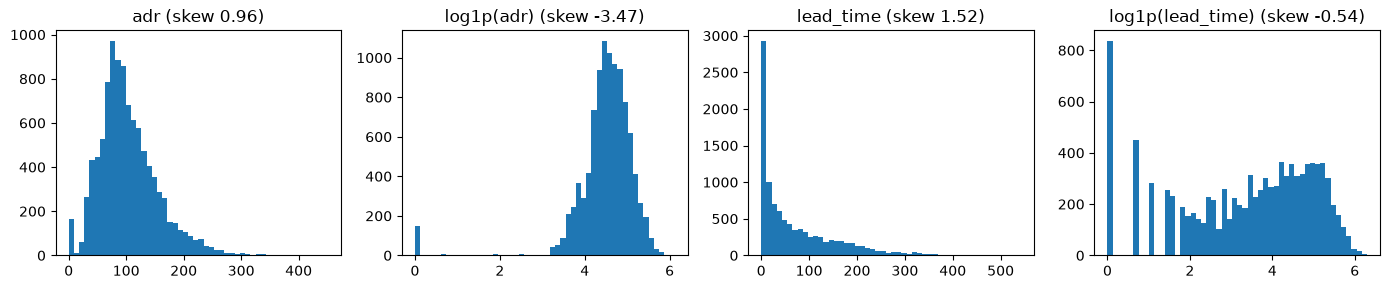

In [90]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, (col, tr, ttl) in zip(ax, [("adr", None, "adr"), ("adr", np.log1p, "log1p(adr)"), ("lead_time", None, "lead_time"), ("lead_time", np.log1p, "log1p(lead_time)")]):
    v = F[col] if tr is None else tr(F[col]); a.hist(v, bins=50); a.set_title(f"{ttl} (skew {v.skew():.2f})")
plt.tight_layout(); plt.show()

In [91]:
log_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "booking_changes", "previous_bookings_not_canceled"]
Fl = F.copy()
for c in log_cols: Fl[c] = np.log1p(Fl[c])
print("skew after log1p:\n", Fl.skew().round(2))
sc = StandardScaler().fit(Fl)
Zl = pd.DataFrame(sc.transform(Fl), columns=feats3, index=F.index)

skew after log1p:
 lead_time                        -0.54
stays_in_weekend_nights           0.13
stays_in_week_nights             -0.11
adults                           -0.26
children                          3.54
adr                               0.96
total_of_special_requests         1.02
booking_changes                   1.97
previous_bookings_not_canceled    5.97
dtype: float64


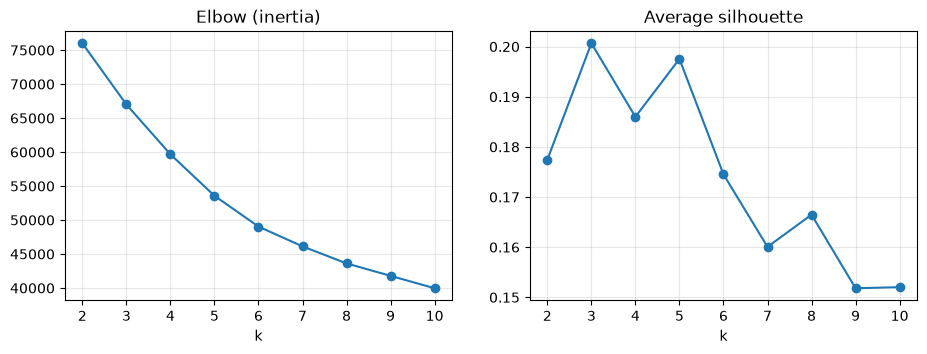

,k,inertia,silhouette
0,2,76014.0,0.177
1,3,67008.0,0.201
2,4,59669.0,0.186
3,5,53572.0,0.198
4,6,49042.0,0.175
5,7,46127.0,0.160
6,8,43620.0,0.166
7,9,41786.0,0.152
8,10,39964.0,0.152


In [92]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=random_state).fit(Zl)
    inertia.append(km.inertia_); sil.append(silhouette_score(Zl, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-"); ax[1].set_title("Average silhouette"); ax[1].set_xlabel("k")
for a in ax: a.grid(alpha=.3)
plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(sil, 3)})

**Elbow and silhouette.** The two plots say different things:
- **Elbow (inertia)** measures how tightly the points hug their own centre. It always falls as k grows, so it only helps if there is a bend. Here the curve declines smoothly (76k, 67k, 60k, 54k, 49k, 46k...) and I cannot see a clear bend. If forced, around k=3 to 6.
- **Silhouette** compares each point's distance to its own cluster with the distance to the next nearest one (1 = well separated, 0 = on the boundary). It peaks at **k=3 (0.201)**, with k=5 close behind (0.198).
- The two methods do not agree, and none of the scores is high. The best silhouette, 0.20, is low: this is a structureless cloud, not neat blobs (see 3.3).

**Choosing k=6.** The silhouette difference between k=3 and k=6 (0.201 vs 0.175) is small, and marketing asked for three to six segments they can name. Three segments would mostly separate "short stays" from "long stays" and would be too coarse to design offers for. I also checked **stability**: for each k, I ran 12 single-initialisation runs and compared each against the best one with the adjusted Rand index. Median agreement is 0.99 for k=3 and k=6, but only 0.47 for k=4 and 0.53 for k=5. So k=4 and k=5 are not reproducible: different starting points give different segments. **k=6 gives the most finely resolved segmentation that is also stable**, which is the reason that matters to a marketer, since segments that change when you re-run them cannot be targeted.

**Initialisations at k=6.** Over 20 runs with a single initialisation each, inertia ranged from 49,042 to 52,318, a spread of **6.7%**. The median run agrees with the best one almost perfectly (ARI 0.99), but the worst run only has ARI 0.46, so some starting points land in a poor local minimum. That is why the final model uses `n_init=20` and keeps the best.

In [93]:
K = 6   # set after reading the plots and the stability check, see the text above
runs = [KMeans(K, n_init=1, init="k-means++", random_state=s).fit(Zl) for s in range(20)]
inert = np.array([r.inertia_ for r in runs])
print("inertia over 20 single initialisations: min %.1f  max %.1f  spread %.2f%%" % (inert.min(), inert.max(), 100 * (inert.max() - inert.min()) / inert.min()))
best = runs[int(np.argmin(inert))]
# do the different runs find the same partition?
aris = [adjusted_rand_score(best.labels_, r.labels_) for r in runs]
print("ARI of each run vs the best run: min %.3f, median %.3f" % (min(aris), np.median(aris)))
km_final = KMeans(K, n_init=20, random_state=random_state).fit(Zl)
labels = km_final.labels_
print("final inertia", round(km_final.inertia_, 1), "| silhouette", round(silhouette_score(Zl, labels), 3))

inertia over 20 single initialisations: min 49041.6  max 52318.3  spread 6.68%
ARI of each run vs the best run: min 0.459, median 0.991


final inertia 49041.6 | silhouette 0.175


### 3.2 Name the segments

Cluster profiles (medians unless noted; sizes are out of 10,000):

In [94]:
samp2 = samp.copy(); samp2["cluster"] = labels
g = samp2.groupby("cluster")
prof = pd.DataFrame({"size": g.size(), "share": (g.size() / len(samp2)).round(3)})
for c in feats3: prof["med_" + c] = g[c].median()
prof["mean_adr"] = g["adr"].mean().round(0)
prof["resort_share"] = g.apply(lambda d: (d.hotel == "Resort Hotel").mean(), include_groups=False).round(2)
prof["top_segment"] = g["market_segment"].agg(lambda s: s.value_counts().index[0])
prof["top_seg_share"] = g["market_segment"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(2)
prof["top_customer_type"] = g["customer_type"].agg(lambda s: s.value_counts().index[0])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
prof.T

cluster,0,1,2,3,4,5
size,1410,2412,2906,776,2190,306
share,0.141,0.241,0.291,0.078,0.219,0.031
med_lead_time,78.0,3.0,89.0,49.5,47.0,3.0
med_stays_in_weekend_nights,1.0,0.0,2.0,1.0,0.0,0.0
med_stays_in_week_nights,3.0,1.0,3.0,2.0,2.0,1.0
med_adults,2.0,2.0,2.0,2.0,2.0,1.0
med_children,0.0,0.0,0.0,1.0,0.0,0.0
med_adr,90.0,80.0,85.5,156.0,129.0,65.0
med_total_of_special_requests,0.0,0.0,0.0,1.0,1.0,0.0
med_booking_changes,1.0,0.0,0.0,0.0,0.0,0.0


In [95]:
from sklearn.metrics import silhouette_samples
ss = silhouette_samples(Zl, labels)
print("silhouette per cluster:"); print(pd.Series(ss).groupby(labels).agg(["mean", "std"]).round(3))

silhouette per cluster:
    mean    std
0  0.082  0.097
1  0.186  0.122
2  0.275  0.110
3  0.139  0.159
4  0.082  0.097
5  0.304  0.161


In [96]:
canc = df[df.is_canceled == 1]
Fc = canc[feats3].astype(float).copy()
for c in log_cols: Fc[c] = np.log1p(Fc[c])
canc_cl = km_final.predict(sc.transform(Fc))
all_cl = pd.concat([pd.Series(labels, index=samp.index), pd.Series(canc_cl, index=canc.index)])
ct = pd.DataFrame({"not_cancelled(10k sample)": pd.Series(labels).value_counts().sort_index(),
                   "cancelled(all)": pd.Series(canc_cl).value_counts().sort_index()})
ct["cancel_share_of_cluster"] = (ct["cancelled(all)"] / (ct["cancelled(all)"] + ct["not_cancelled(10k sample)"] * len(notc) / 10000)).round(3)
print("Cancel rate computed with the sample scaled back up to all", len(notc), "non-cancelled bookings")
ct

Cancel rate computed with the sample scaled back up to all 62648 non-cancelled bookings


/opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


,not_cancelled(10k sample),cancelled(all),cancel_share_of_cluster
0,1410,1874,0.175
1,2412,3116,0.171
2,2906,10545,0.367
3,776,2777,0.364
4,2190,5309,0.279
5,306,105,0.052


| cluster | size | what the numbers say | name | offer |
|---|---|---|---|---|
| 5 | 306 (3%) | 1 adult, lead time 3 days, 1 weeknight, adr 61, 4 earlier stays, 58% corporate, silhouette 0.30 | **Solo business regulars** | Corporate loyalty rate with breakfast and late checkout included |
| 1 | 2,412 (24%) | Lead time 3 days, 1 weeknight, no weekend, adr 80 | **Last-minute midweek stopovers** | Same-day midweek rate pushed through online agents |
| 2 | 2,906 (29%) | Lead time 89 days, 2 weekend nights + 3 weeknights, adr 86, no requests; the best-defined segment (silhouette 0.28) | **Early-booked budget holidaymakers** | Early-bird price lock plus a pre-pay discount |
| 3 | 776 (8%) | Median 1 child, adr 156, lead time 50 days, 1 request, 67% online agent | **Families who pay for space** | Family package with kids-eat-free and connecting rooms |
| 4 | 2,190 (22%) | Lead time 47 days, adr 129, 1 request, 81% online agent, only 28% resort | **City-break couples who book through online agents** | Add-on bundle at booking (dinner, spa) rather than a discount, since they already pay more |
| 0 | 1,410 (14%) | Lead time 78 days, **1 booking change** (the only cluster that changes bookings), adr 90 | **Planners who keep tweaking** | Free date-change guarantee in return for a prepayment |

**Cluster I trust least: 0 and 4, tied.** Both have an average silhouette of about 0.08, close to zero, meaning many of their members sit nearly as close to another cluster. Of the two I trust cluster 0 least, since its main distinguishing feature (a median of one booking change) is a median of a very skewed count. Treat "tweaking planners" as a hypothesis, not a finding. Cluster 5 (silhouette 0.30) and cluster 2 (0.28) are the most reliable.

**Cancelled bookings.** I assign every cancelled booking to its nearest centroid (using the same log transform and scaling) and compute each cluster's cancel share, scaling the 10,000-row sample back up to all 62,648 non-cancelled bookings:

| cluster | cancel share |
|---|---|
| 5 Solo business regulars | **5%** |
| 1 Last-minute midweek stopovers | 17% |
| 0 Planners who keep tweaking | 18% |
| 4 City-break couples (online agents) | 28% |
| 3 Families who pay for space | **36%** |
| 2 Early-booked budget holidaymakers | **37%** |

**What this adds beyond Part 2.** Part 2 said *which features* predict cancellation (lead time, agent, country). The segments say *which kinds of guests* cancel: the early-booked holidaymakers and the families, about 37% each, against 5% for business regulars and 17% for last-minute guests. That is actionable differently: the revenue team can overbook harder against segments 2 and 3, and marketing can aim the non-refundable or pre-pay offers at them (a deposit tied to the "early-bird price lock" would hit exactly the group that cancels most). Segments also reveal that cancellation tracks planning horizon, not wealth: the high-adr families and the low-adr holidaymakers cancel equally often.

**Caveat.** The cancel rates depend on the clusters being real, and 3.3 questions that. The cancelled bookings are assigned to the nearest centroid and were not used to build the clusters, so there is no circularity, but segments with a silhouette this low have fuzzy edges.

MinPts = 18 | knee at rank 8784 of 10000 -> k-distance 1.773


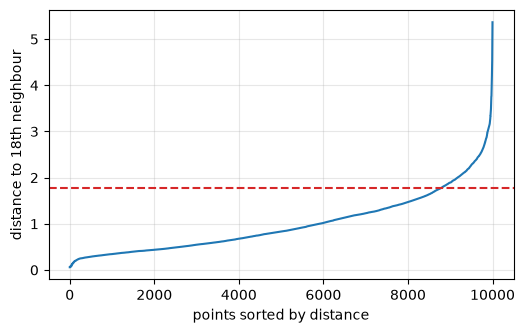

k-distance percentiles: {50: 0.83, 75: 1.34, 90: 1.89, 95: 2.27, 99: 3.04}


In [97]:
from sklearn.neighbors import NearestNeighbors
minpts = 2 * len(feats3)
nn = NearestNeighbors(n_neighbors=minpts).fit(Zl)
kd = np.sort(nn.kneighbors(Zl)[0][:, -1])
# knee = point of the curve farthest from the straight line joining its two ends
x = np.arange(len(kd)); line = kd[0] + (kd[-1] - kd[0]) * x / (len(kd) - 1)
knee = int(np.argmax(np.abs(kd - line)))
print("MinPts =", minpts, "| knee at rank", knee, "of", len(kd), "-> k-distance", round(kd[knee], 3))
plt.figure(figsize=(6, 3.5)); plt.plot(kd); plt.axhline(kd[knee], color="C3", ls="--")
plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to {minpts}th neighbour"); plt.grid(alpha=.3); plt.show()
print("k-distance percentiles:", {p: round(float(np.percentile(kd, p)), 2) for p in [50, 75, 90, 95, 99]})

In [98]:
def run_db(eps):
    d = DBSCAN(eps=eps, min_samples=minpts).fit(Zl)
    nclu = len(set(d.labels_)) - (1 if -1 in d.labels_ else 0)
    return d, nclu, int((d.labels_ == -1).sum())
for e in [0.8, 1.0, 1.2, 1.5, 2.0]:
    _, nclu, nn_ = run_db(e); print(f"eps={e}: clusters={nclu}, noise={nn_}")

eps=0.8: clusters=26, noise=4195


eps=1.0: clusters=35, noise=3025


eps=1.2: clusters=16, noise=2061


eps=1.5: clusters=11, noise=1006


eps=2.0: clusters=3, noise=320


In [99]:
EPS = 2.0   # read off the k-distance plot (knee is at about 2.07), see text
db, nclu, nnoise = run_db(EPS)
print("eps", EPS, "| clusters:", nclu, "| noise points:", nnoise, f"({nnoise/len(Zl):.1%})")
print("DBSCAN cluster sizes (label -1 = noise):", dict(zip(*np.unique(db.labels_, return_counts=True))))
print("ARI k-means vs DBSCAN (noise as its own label):", round(adjusted_rand_score(labels, db.labels_), 3))
print(pd.crosstab(labels, db.labels_, rownames=["kmeans"], colnames=["dbscan"]))

eps 2.0 | clusters: 3 | noise points: 320 (3.2%)
DBSCAN cluster sizes (label -1 = noise): {np.int64(-1): np.int64(320), np.int64(0): np.int64(8957), np.int64(1): np.int64(282), np.int64(2): np.int64(441)}
ARI k-means vs DBSCAN (noise as its own label): 0.091
dbscan   -1     0    1    2
kmeans                     
0        54  1313    0   43
1        12  2381    0   19
2         8  2878    0   20
3       136     0  282  358
4        37  2152    0    1
5        73   233    0    0


variance explained by 2 PCs: [0.237 0.156]


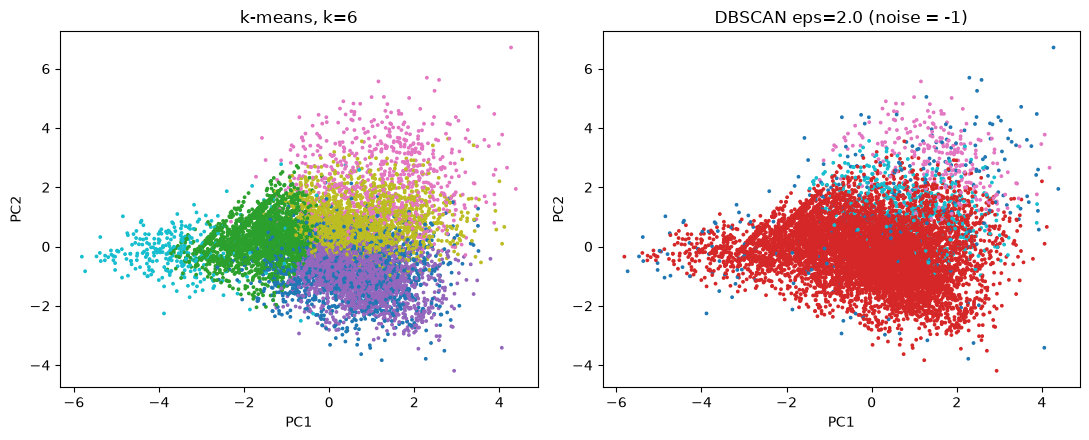

In [100]:
from sklearn.decomposition import PCA
pca = PCA(2, random_state=random_state).fit(Zl); P = pca.transform(Zl)
print("variance explained by 2 PCs:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(P[:, 0], P[:, 1], c=labels, s=3, cmap="tab10"); ax[0].set_title(f"k-means, k={K}")
ax[1].scatter(P[:, 0], P[:, 1], c=db.labels_, s=3, cmap="tab10"); ax[1].set_title(f"DBSCAN eps={EPS} (noise = -1)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

### 3.3 Are the groups real?

**Choosing eps.** MinPts = 2 x 9 features = 18. The k-distance plot (distance to the 18th neighbour, sorted) rises slowly then bends upward at around **1.8 to 2.1** (the automated knee is at 1.77; the percentiles show 90% of points have an 18th neighbour within 1.89). I use **eps = 2.0**. DBSCAN is very sensitive to eps here: eps 0.8 gives 26 clusters and 42% noise, 1.0 gives 35 clusters, 1.5 gives 11, and 2.0 gives 3. That sensitivity is itself a warning sign.

**Result at eps = 2.0:** **3 clusters and 320 noise points (3.2%)**. One cluster contains **8,957** of 10,000 bookings (90%). The other two hold 282 and 441, and the 282 cluster is almost entirely k-means cluster 3, the families.

**Adjusted Rand index (k-means vs DBSCAN, noise as its own label): 0.091.** That is close to zero, meaning the two labelings share almost nothing beyond chance. K-means cut the big DBSCAN cluster into five pieces (see the crosstab), while DBSCAN sees one connected mass.

**Do the guests fall into natural groups? Mostly no.** Evidence:
- The best average silhouette is only 0.20 (0.175 at k=6), and the two weakest clusters sit at 0.08.
- At a sensible eps, DBSCAN finds one blob with 90% of the points. At smaller eps it shatters into dozens of small clusters with up to 40% noise. There is no eps where it returns a clean set of segments.
- The PCA plot (two components explain only 24% and 16% of the variance, so it is a limited view) shows one dense cloud, with the k-means colours as slices of it rather than separate islands.
- One real exception: the families (a distinct, dense group with high adr and children) and, to a lesser degree, the solo business regulars separate from the rest.

So k-means mostly cut a continuous cloud into six pieces, which is a perfectly legitimate thing to do for marketing, but the cuts are conventions.

**For marketing:** treat the segment names as handy labels for slices of a continuum, to be tested with small campaigns, not as "types of person", except families and business regulars, which look real.

## Part 4. The final test and the memo

In [101]:
final_name = res_all.sort_values("cost").model.iloc[0]
thr = res_all.set_index("model").loc[final_name, "threshold"]
print("final model chosen on CV cost alone:", final_name, "| CV threshold:", round(thr, 3))
print(res_all.sort_values("cost")[["model", "AUC", "cost_per_booking"]].round(3).to_string(index=False))
final_pipe = clone(ensembles[final_name]) if final_name in ensembles else None
final_pipe.fit(Xtr, ytr)
Xte = X_test[feat_cols]
p_te = final_pipe.predict_proba(Xte)[:, 1]
pred_te = (p_te >= thr).astype(int)
yte = np.asarray(y_test)
cost_model_test = total_cost(yte, pred_te)
cost_nobody_test = 120 * int(yte.sum()); cost_every_test = 150 * int((yte == 0).sum())
test_tab = pd.DataFrame({
    "policy": [final_name, "overbook nobody", "overbook everybody"],
    "total_cost": [cost_model_test, cost_nobody_test, cost_every_test],
    "cost_per_booking": np.round(np.array([cost_model_test, cost_nobody_test, cost_every_test]) / len(yte), 2)})
test_tab["AUC"] = [roc_auc_score(yte, p_te), np.nan, np.nan]
test_tab["recall"] = [recall_score(yte, pred_te), 0.0, 1.0]
test_tab["precision"] = [precision_score(yte, pred_te), np.nan, yte.mean()]
cv_row = res_all.set_index("model").loc[final_name]
print(f"CV cost per booking {cv_row.cost_per_booking:.2f}  vs  test cost per booking {cost_model_test/len(yte):.2f}")
test_tab.round(3)

final model chosen on CV cost alone: Random forest (200 trees) | CV threshold: 0.515
                    model   AUC  cost_per_booking
Random forest (200 trees) 0.892            21.294
 Bagging, unlimited trees 0.885            21.785
  Boosting, depth-2 trees 0.872            23.406
Boosting, unlimited trees 0.875            23.613
 SVM (RBF, 20k subsample) 0.852            23.679
      Logistic regression 0.831            26.990
  Single tree, depth None 0.726            29.802
   Bagging, depth-2 trees 0.755            30.499
     Single tree, depth 2 0.688            33.364


CV cost per booking 21.29  vs  test cost per booking 21.22


,policy,total_cost,cost_per_booking,AUC,recall,precision
0,Random forest (200 trees),366600,21.22,0.891,0.601,0.754
1,overbook nobody,569400,32.96,NaN,0.000,NaN
2,overbook everybody,1879500,108.80,NaN,1.000,0.275


In [102]:
yr = year_all.loc[X.index]
tr_m = yr.isin([2015, 2016]).values; te_m = (yr == 2017).values
Xa, ya = X[feat_cols], y
Xa_tr, ya_tr, Xa_te, ya_te = Xa[tr_m], ya[tr_m], Xa[te_m], ya[te_m]
# threshold chosen by CV inside the 2015-2016 data only
oof_t = cross_val_predict(clone(ensembles[final_name]), Xa_tr, ya_tr, cv=cv5, method="predict_proba", n_jobs=5)[:, 1]
thr_t, cv_cost_t = best_threshold(ya_tr, oof_t)
mt = clone(ensembles[final_name]).fit(Xa_tr, ya_tr)
pt = mt.predict_proba(Xa_te)[:, 1]
pred_t = (pt >= thr_t).astype(int)
yt = np.asarray(ya_te)
c_model = total_cost(yt, pred_t); c_no = 120 * int(yt.sum()); c_all = 150 * int((yt == 0).sum())
tt = pd.DataFrame({"policy": [final_name, "overbook nobody", "overbook everybody"],
                   "cost_per_booking": np.round(np.array([c_model, c_no, c_all]) / len(yt), 2)})
tt["AUC"] = [roc_auc_score(yt, pt), np.nan, np.nan]
tt["recall"] = [recall_score(yt, pred_t), 0, 1]; tt["precision"] = [precision_score(yt, pred_t), np.nan, yt.mean()]
print("train rows", tr_m.sum(), "| test rows (2017)", te_m.sum(), "| threshold", round(thr_t, 3), "| CV cost/booking inside 2015-16:", round(cv_cost_t / len(ya_tr), 2))
print("saving vs overbook nobody per booking: random split €%.2f | time split €%.2f" % ((cost_nobody_test - cost_model_test) / len(y_test), (c_no - c_model) / len(yt)))
tt.round(3)

train rows 54932 | test rows (2017) 31442 | threshold 0.51 | CV cost/booking inside 2015-16: 17.78
saving vs overbook nobody per booking: random split €11.74 | time split €7.60


,policy,cost_per_booking,AUC,recall,precision
0,Random forest (200 trees),30.63,0.815,0.399,0.713
1,overbook nobody,38.23,NaN,0.000,NaN
2,overbook everybody,102.22,NaN,1.000,0.319


In [103]:
d = df.copy(); d["year"] = year_all
months = ["January","February","March","April","May","June","July","August"]
same = d[d.arrival_date_month.isin(months) & d.year.isin([2016, 2017])]   # Jan-Aug, the only months both years have
print("Jan-Aug only, so the seasons match. Cancel rate and mix by year:")
summ = same.groupby("year").agg(n=("is_canceled", "size"), cancel_rate=("is_canceled", "mean"), lead_time=("lead_time", "mean"), adr=("adr", "mean"),
                                 nonrefund=("deposit_type", lambda s: (s == "Non Refund").mean()),
                                 online_ta=("market_segment", lambda s: (s == "Online TA").mean()),
                                 groups=("market_segment", lambda s: (s == "Groups").mean()),
                                 no_agent=("has_agent", lambda s: 1 - s.mean()), repeated=("is_repeated_guest", "mean"))
print(summ.round(3).T)
print("\nCancel rate by deposit type and year (Jan-Aug):"); print(same.groupby(["deposit_type", "year"]).is_canceled.agg(["mean", "count"]).round(3).unstack())
print("\nCancel rate by market segment and year (Jan-Aug):"); print(same.groupby(["market_segment", "year"]).is_canceled.agg(["mean", "count"]).round(3).unstack())
print("\nCancel rate by hotel and year (Jan-Aug):"); print(same.groupby(["hotel", "year"]).is_canceled.agg(["mean", "count"]).round(3).unstack())

Jan-Aug only, so the seasons match. Cancel rate and mix by year:
year              2016       2017
n            27495.000  31442.000
cancel_rate      0.255      0.319
lead_time       71.773     93.839
adr            104.460    119.348
nonrefund        0.010      0.011
online_ta        0.597      0.651
groups           0.038      0.048
no_agent         0.135      0.118
repeated         0.034      0.041

Cancel rate by deposit type and year (Jan-Aug):
               mean         count       
year           2016   2017   2016   2017
deposit_type                            
No Deposit    0.250  0.311  27144  31083
Non Refund    0.855  0.982    283    336
Refundable    0.029  0.957     68     23

Cancel rate by market segment and year (Jan-Aug):
                 mean         count       
year             2016   2017   2016   2017
market_segment                            
Aviation        0.206  0.194     63    103
Complementary   0.117  0.143    188    196
Corporate       0.097  0.135   136

In [104]:
# Non-refundable bookings over time, and the agents behind them
d["ym"] = d.year.astype(str) + "-" + d.arrival_date_month.map({m: i for i, m in enumerate(["January","February","March","April","May","June","July","August","September","October","November","December"], 1)}).astype(str).str.zfill(2)
nr_t = d.groupby("year").apply(lambda g: pd.Series({"NR_share": (g.deposit_type == "Non Refund").mean(), "NR_cancel_rate": g[g.deposit_type == "Non Refund"].is_canceled.mean(), "NR_n": (g.deposit_type == "Non Refund").sum()}), include_groups=False)
print(nr_t.round(3))
print("\ncancel rate by arrival month, 2016 vs 2017"); print(d.pivot_table(index="arrival_date_month", columns="year", values="is_canceled", aggfunc="mean").reindex(["January","February","March","April","May","June","July","August"]).round(3))

      NR_share  NR_cancel_rate   NR_n
year                                 
2015     0.018           0.974  230.0
2016     0.011           0.904  450.0
2017     0.011           0.982  336.0

cancel rate by arrival month, 2016 vs 2017


year                 2015   2016   2017
arrival_date_month                     
January               NaN  0.163  0.259
February              NaN  0.187  0.269
March                 NaN  0.232  0.256
April                 NaN  0.267  0.335
May                   NaN  0.247  0.327
June                  NaN  0.259  0.338
July                0.306  0.284  0.352
August              0.234  0.327  0.367


In [105]:
# the two biggest agents, by year (all months): who is driving the 2017 rise?
print(d[d.agent.isin(["9", "240"])].groupby(["agent", "year"]).is_canceled.agg(["count", "mean"]).round(3).unstack(0))
print("\nshare of bookings from agents 9 and 240:"); print(d.groupby("year").agent.apply(lambda s: s.isin(["9", "240"]).mean()).round(3))

      count          mean       
agent   240      9    240      9
year                            
2015   2385   2110  0.293  0.261
2016   5890  14706  0.367  0.386
2017   4603  11764  0.445  0.443

share of bookings from agents 9 and 240:
year
2015    0.343
2016    0.492
2017    0.521
Name: agent, dtype: float64


In [106]:
n_months = 26   # July 2015 - August 2017
bookings_per_month = len(df) / n_months
save_pb = (cost_nobody_test - cost_model_test) / len(y_test)         # random-split saving per booking
save_pb_t = (c_no - c_model) / len(yt)                               # time-split saving per booking
tp = int(((pred_te == 1) & (yte == 1)).sum()); fp = int(((pred_te == 1) & (yte == 0)).sum())
tp_t = int(((pred_t == 1) & (yt == 1)).sum()); fp_t = int(((pred_t == 1) & (yt == 0)).sum())
memo = dict(final_model=final_name, threshold=float(thr), bookings_per_month=bookings_per_month,
            share_flagged=float(pred_te.mean()), share_flagged_time=float(pred_t.mean()),
            save_per_booking_random=save_pb, save_per_booking_time=save_pb_t,
            save_per_month_random=save_pb * bookings_per_month, save_per_month_time=save_pb_t * bookings_per_month,
            cost_per_booking_nobody=cost_nobody_test / len(y_test), cost_per_booking_all=cost_every_test / len(y_test),
            cost_per_booking_model=cost_model_test / len(y_test), cost_per_booking_model_time=c_model / len(yt),
            cost_per_booking_nobody_time=c_no / len(yt), cost_per_booking_all_time=c_all / len(yt),
            rooms_right_per_month=tp / len(y_test) * bookings_per_month, rooms_wrong_per_month=fp / len(y_test) * bookings_per_month,
            rooms_right_per_month_time=tp_t / len(yt) * bookings_per_month, rooms_wrong_per_month_time=fp_t / len(yt) * bookings_per_month,
            precision=float(precision_score(yte, pred_te)), recall=float(recall_score(yte, pred_te)),
            precision_time=float(precision_score(yt, pred_t)), recall_time=float(recall_score(yt, pred_t)),
            auc=float(roc_auc_score(yte, p_te)), auc_time=float(roc_auc_score(yt, pt)))
json.dump(memo, open("memo_numbers.json", "w"), indent=1)
for k, v in memo.items(): print(k, v if isinstance(v, str) else round(v, 3))

final_model Random forest (200 trees)
threshold 0.515
bookings_per_month 3322.077
share_flagged 0.219
share_flagged_time 0.178
save_per_booking_random 11.74
save_per_booking_time 7.599
save_per_month_random 38999.548
save_per_month_time 25243.643
cost_per_booking_nobody 32.961
cost_per_booking_all 108.799
cost_per_booking_model 21.221
cost_per_booking_model_time 30.628
cost_per_booking_nobody_time 38.227
cost_per_booking_all_time 102.217
rooms_right_per_month 548.071
rooms_wrong_per_month 178.459
rooms_right_per_month_time 422.735
rooms_wrong_per_month_time 169.897
precision 0.754
recall 0.601
precision_time 0.713
recall_time 0.399
auc 0.891
auc_time 0.815


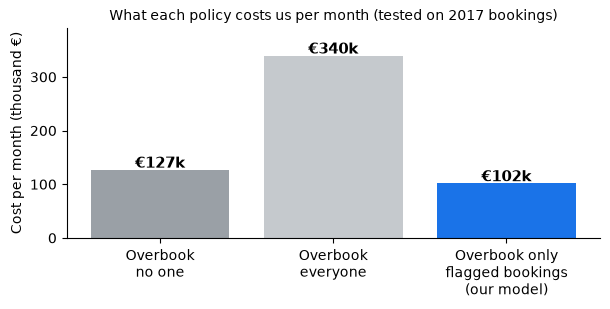

In [107]:
# The one chart for the memo: monthly cost of each policy, in euros
labels_ = ["Overbook\nno one", "Overbook\neveryone", "Overbook only\nflagged bookings\n(our model)"]
vals = np.array([memo["cost_per_booking_nobody_time"], memo["cost_per_booking_all_time"], memo["cost_per_booking_model_time"]]) * memo["bookings_per_month"]
fig, ax = plt.subplots(figsize=(6.2, 3.2))
bars = ax.bar(labels_, vals / 1000, color=["#9aa0a6", "#c5c9cd", "#1a73e8"])
for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v / 1000 + 4, f"€{v/1000:,.0f}k", ha="center", fontsize=11, fontweight="bold")
ax.set_ylabel("Cost per month (thousand €)"); ax.set_title("What each policy costs us per month (tested on 2017 bookings)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); ax.set_ylim(0, vals.max() / 1000 * 1.15)
plt.tight_layout(); plt.savefig("memo_chart.png", dpi=200); plt.show()

### 4.1 Results

**Final model, chosen using only CV results from Parts 1 and 2:** the **200-tree random forest**, the lowest CV cost (€21.29 per booking), with the cost-minimising CV threshold of **0.515**. Refit on the full training set and scored once on the untouched holdout:

| policy | cost per booking | total cost (17,275 test bookings) | recall | precision | AUC |
|---|---|---|---|---|---|
| Random forest, threshold 0.515 | **€21.22** | €366,600 | 0.60 | 0.75 | 0.891 |
| Overbook nobody | €32.96 | €569,400 | 0 | - | - |
| Overbook everybody | €108.80 | €1,879,500 | 1.00 | 0.28 | - |

The test cost (€21.22) is essentially identical to the CV cost (€21.29), so there is no sign of overfitting to the CV or to the threshold. The model saves about **36%** against overbooking nobody.

**Time-based split.** Train on 2015 and 2016 arrivals (54,932 bookings), test on 2017 (31,442). The threshold is chosen by CV inside 2015 to 2016 only.

| policy | cost per booking | recall | precision | AUC |
|---|---|---|---|---|
| Random forest | **€30.63** | 0.40 | 0.71 | 0.815 |
| Overbook nobody | €38.23 | 0 | - | - |
| Overbook everybody | €102.22 | 1.00 | 0.32 | - |

**Which number should the director believe? The time-based one.** The random split mixes 2015 to 2017 bookings in both train and test, so the model has seen the same season, the same agents and the same pricing regime it is tested on. The hotel will instead score *future* bookings. The time split reproduces that: AUC falls from 0.89 to 0.82, recall from 0.60 to 0.40, and the saving per booking from €11.74 to **€7.60**, about a third less. Even so, the model still beats doing nothing in 2017 (€30.63 vs €38.23). Note a limitation: 2017 only covers January to August, and the first-half-year mix differs from the whole year.

**What changed in 2017? Cancellation got more common, in a way a model trained on earlier years did not anticipate.** Comparing January to August only, so the seasons match:
- **Cancel rate rose from 25.5% (2016) to 31.9% (2017)**, and it rose in every single month, from +2.4 points in March to +9.6 in January.
- It rose in both hotels (City 27.7% to 33.9%, Resort 21.9% to 28.2%) and mainly in the Online TA segment (33.0% to 39.6%).
- **The mix moved toward the riskiest bookings:** mean lead time rose from 72 to 94 days, mean adr from €104 to €119, and the Online TA share from 59.7% to 65.1%.
- **The two biggest agents (9 and 240)** went from 49% of bookings in 2016 to 52% in 2017 and their cancel rates rose to 44% (from 39% and 37%).
- Deposit policy mix did not change (non-refundable about 1.0 to 1.1% of bookings), so this is not a policy effect.

So the model, trained when 25% cancelled, under-predicts cancellations in 2017 (recall dropped to 0.40) because the same booking now cancels more often than it used to. That is a drift in behaviour the data cannot explain by itself, so the model needs retraining on recent bookings.

### 4.2 Memo

The memo is the separate file `Assignment_3_memo.pdf` in this folder. Its numbers come from the time-split results above, and they are saved by the notebook to `memo_numbers.json`.